# Task 3: Kakuro như một bài toán CSP

Notebook này chạy các thực nghiệm của phần giải Kakuro: kiểm tra cấu trúc bảng, giải bảng 5x5 và 9x9 của đề, so sánh các cấu hình heuristic, kiểm tra độ ổn định và các bảng đặc biệt.

## 1. Mô hình CSP

- **Biến:** mỗi ô trắng $(r, c)$.
- **Miền:** $\{1, \dots, 9\}$, được thu hẹp dần bằng lan truyền ràng buộc.
- **Ràng buộc:** với mỗi *run* (dãy ô trắng liên tiếp theo hàng hoặc cột): các giá trị **khác nhau đôi một** và **tổng bằng gợi ý** của run. Đây là ràng buộc n-ary (nhiều biến cùng lúc), và mỗi ô trắng thuộc đúng hai run (một ngang, một dọc).

Giải bằng: lọc tổ hợp hợp lệ của từng run theo các giá trị đã gán (lan truyền ràng buộc), kết hợp backtracking search với MRV, Degree và LCV.

In [1]:
from collections import Counter
from board import Board
from solver import KakuroSolver
from events import event_bus
from validator import Validator
from experiments import (compare_configs, results_table, stability_test, run_config,
                         count_solutions, is_fully_valid, format_table)
from puzzles import (SAMPLE_5X5, SAMPLE_9X9, UNSOLVABLE_COMBO, UNSOLVABLE_SEARCH, MULTI_SOLUTION)

## 2. Kiểm tra cấu trúc bảng

Bảng đúng phải có mỗi ô trắng thuộc đúng 2 run và tổng gợi ý ngang bằng tổng gợi ý dọc. Với 5x5: 12 ô trắng, 8 run, tổng 60. Với 9x9: 48 ô trắng, 28 run, tổng 249.

In [2]:
for name, grid, expected in (('5x5', SAMPLE_5X5, (12, 8, 60, 60)), ('9x9', SAMPLE_9X9, (48, 28, 249, 249))):
    print('Bảng', name)
    stats = Board(grid).print_structure_stats()
    assert stats == expected
    print('OK\n')

Bảng 5x5
Số ô trắng: 12
Số run: 8
Tổng ngang: 60
Tổng dọc: 60
OK

Bảng 9x9
Số ô trắng: 48
Số run: 28
Tổng ngang: 249
Tổng dọc: 249
OK



## 3. Giải bảng 5x5 và 9x9 (MRV, không LCV)

In [3]:
for name, grid in (('5x5', SAMPLE_5X5), ('9x9', SAMPLE_9X9)):
    board = Board(grid)
    solver = KakuroSolver(board)
    ok = solver.solve()
    print(f'Bảng {name}: giải được = {ok}, hợp lệ (Validator) = {is_fully_valid(board)}')
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in solver.get_stats().items()})
    board.display()
    print()

Bảng 5x5: giải được = True, hợp lệ (Validator) = True
{'assignments': 28, 'backtracks': 16, 'domain_updates': 27, 'execution_time': 0.0012, 'hit_limit': False}
[\] [\] [\21] [\14] [\]
[\] [12\14]   8     4   [\11]
[21\]   9     3     1     8  
[11\]   5     1     2     3  
[\] [16\]   9     7   [\]

Bảng 9x9: giải được = True, hợp lệ (Validator) = True
{'assignments': 169, 'backtracks': 121, 'domain_updates': 133, 'execution_time': 0.0152, 'hit_limit': False}
[\] [\] [\44] [\16] [\9] [\] [\15] [\44] [\]
[\] [22\]   5     9     8   [3\11]   1     2   [\14]
[\] [28\17]   2     7     1     3     4     6     5  
[14\]   8     6   [\] [20\12]   1     2     8     9  
[17\]   9     8   [22\29]   3     2     8     9   [\7]
[\] [28\12]   9     8     6     5   [12\]   7     5  
[14\]   3     4     5     2   [\7] [6\12]   4     2  
[39\]   9     3     7     1     6     8     5   [\]
[\] [16\]   7     9   [8\]   1     4     3   [\]



## 4. So sánh các cấu hình heuristic trên bảng 9x9

Mọi cấu hình đều bật lan truyền ràng buộc và dùng cùng một bảng, cùng giới hạn 50000 lần gán. Cấu hình chạm giới hạn được ghi là *giới hạn* (không tìm được nghiệm trong số bước cho phép).

In [4]:
configs = [(v, l, True) for v in ('none', 'mrv', 'degree', 'mrv_degree') for l in ('none', 'lcv')]
results = compare_configs(SAMPLE_9X9, configs, max_assignments=50000)
print(results_table(results))

Chọn biến  | Chọn giá trị | Lan truyền | Giải được | Lần gán | Quay lui | Cắt miền | Thời gian (s)
-----------+--------------+------------+-----------+---------+----------+----------+--------------
none       | none         | có         | có        | 759     | 711      | 434      | 0.0289       
none       | lcv          | có         | có        | 169     | 121      | 127      | 0.0075       
mrv        | none         | có         | có        | 169     | 121      | 133      | 0.0069       
mrv        | lcv          | có         | có        | 2474    | 2426     | 1140     | 0.1016       
degree     | none         | có         | giới hạn  | 50000   | 49979    | 17268    | 2.4786       
degree     | lcv          | có         | giới hạn  | 50000   | 49984    | 33545    | 3.4479       
mrv_degree | none         | có         | có        | 260     | 212      | 157      | 0.0111       
mrv_degree | lcv          | có         | có        | 660     | 612      | 324      | 0.0293       


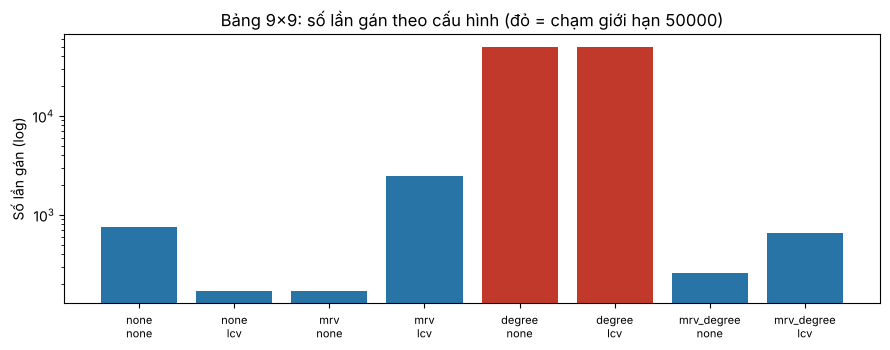

In [5]:
import matplotlib.pyplot as plt

labels = [f"{r['var']}\n{r['val']}" for r in results]
values = [r['assignments'] for r in results]
colors = ['#c0392b' if r['hit_limit'] else '#2874a6' for r in results]
plt.figure(figsize=(9, 3.6))
plt.bar(range(len(values)), values, color=colors)
plt.yscale('log')
plt.xticks(range(len(values)), labels, fontsize=8)
plt.ylabel('Số lần gán (log)')
plt.title('Bảng 9x9: số lần gán theo cấu hình (đỏ = chạm giới hạn 50000)')
plt.tight_layout()
plt.show()

**Nhận xét (trên bảng 9x9 duy nhất của đề).**

- MRV cho kết quả tốt nhất trong các cấu hình đo được: 169 lần gán.
- Tác dụng của LCV *không nhất quán*: khi chọn biến theo thứ tự cố định thì LCV giảm số lần gán từ 759 xuống 169, nhưng khi kết hợp với MRV thì tăng từ 169 lên 2474. Vì chỉ đo trên một bảng, ta chỉ kết luận được là LCV không đáng tin trên bảng này. Một giả thuyết cần kiểm chứng thêm: với ràng buộc khác nhau trong run, điểm LCV của các giá trị thường gần nhau nên thứ tự thử ít mang thông tin.
- Degree dùng một mình chạm giới hạn 50000 lần gán, vì không dựa vào kích thước miền nên không tận dụng được kết quả lan truyền (giả thuyết).
- MRV kết hợp Degree để phá hòa (260 lần gán) cùng bậc với MRV.

## 5. Tắt lan truyền ràng buộc

Chỉ còn backtracking kiểm tra tổng và trùng khi gán. Giới hạn 200000 lần gán.

In [6]:
no_prop = [(v, 'none', False) for v in ('none', 'mrv')]
print(results_table(compare_configs(SAMPLE_9X9, no_prop, max_assignments=200000)))

Chọn biến | Chọn giá trị | Lan truyền | Giải được | Lần gán | Quay lui | Cắt miền | Thời gian (s)
----------+--------------+------------+-----------+---------+----------+----------+--------------
none      | none         | không      | có        | 186504  | 186456   | 0        | 1.7297       
mrv       | none         | không      | có        | 186504  | 186456   | 0        | 1.6485       


Khi tắt lan truyền, mọi miền đều còn 9 giá trị nên MRV luôn hòa và chọn ô đầu tiên, vì vậy hai cấu hình cho cùng số lần gán. So với 169 lần gán khi bật lan truyền, lan truyền ràng buộc giảm số lần gán hơn 1000 lần.

## 6. Độ ổn định

Chạy lặp 20 lần cùng một cấu hình: nghiệm và số liệu tìm kiếm phải giống nhau mọi lần; chỉ thời gian dao động.

In [7]:
for name, grid in (('5x5', SAMPLE_5X5), ('9x9', SAMPLE_9X9)):
    s = stability_test(grid, 'mrv', 'none', True, repeats=20)
    print(name, {k: (round(v, 5) if isinstance(v, float) else v) for k, v in s.items()})

5x5 {'repeats': 20, 'all_valid': True, 'same_solution': True, 'same_counts': True, 'mean_time': 0.00092, 'std_time': 0.00065, 'assignments': 28, 'backtracks': 16}


9x9 {'repeats': 20, 'all_valid': True, 'same_solution': True, 'same_counts': True, 'mean_time': 0.00992, 'std_time': 0.0061, 'assignments': 169, 'backtracks': 121}


## 7. Bảng đặc biệt và kiểm chứng độc lập

`count_solutions` là bộ đếm nghiệm vét cạn viết riêng, không dùng `KakuroSolver`.

In [8]:
for name, grid in (('vô nghiệm (hết tổ hợp)', UNSOLVABLE_COMBO), ('vô nghiệm (phải tìm kiếm)', UNSOLVABLE_SEARCH)):
    r = run_config(grid)
    print(f"{name}: solver trả về {r['solved']} (kỳ vọng False); số nghiệm vét cạn = {count_solutions(grid)}")
r = run_config(MULTI_SOLUTION)
print(f"nhiều nghiệm: solver trả về {r['solved']}, hợp lệ = {r['valid']}; số nghiệm vét cạn = {count_solutions(MULTI_SOLUTION, limit=10)} (kỳ vọng 2)")
print(f"Bảng đề: 5x5 có {count_solutions(SAMPLE_5X5)} nghiệm, 9x9 có {count_solutions(SAMPLE_9X9)} nghiệm (dừng đếm ở 2)")

vô nghiệm (hết tổ hợp): solver trả về False (kỳ vọng False); số nghiệm vét cạn = 0
vô nghiệm (phải tìm kiếm): solver trả về False (kỳ vọng False); số nghiệm vét cạn = 0
nhiều nghiệm: solver trả về True, hợp lệ = True; số nghiệm vét cạn = 2 (kỳ vọng 2)


Bảng đề: 5x5 có 1 nghiệm, 9x9 có 1 nghiệm (dừng đếm ở 2)


## 8. Luồng sự kiện cho giao diện

Solver phát sự kiện qua `event_bus`; UI chỉ đăng ký một listener, thu lại và phát lại theo tốc độ riêng. Xem `EVENTS.md`.

In [9]:
recorded = []
listener = lambda event_type, data: recorded.append((event_type, data))
event_bus.subscribe(listener)
board = Board(SAMPLE_5X5)
KakuroSolver(board).solve()
event_bus.unsubscribe(listener)

print('Số sự kiện theo loại:', dict(Counter(t for t, _ in recorded)))
print()
for event_type, data in recorded[:6]:
    short = {k: (v if k != 'domains' else '...') for k, v in data.items()}
    print(event_type, short)
print('...')
print(recorded[-1][0], {k: v for k, v in recorded[-1][1].items() if k != 'solution'})

Số sự kiện theo loại: {'INIT': 1, 'DOMAIN_UPDATE': 27, 'ASSIGN': 28, 'BACKTRACK': 16, 'SOLVED': 1}

INIT {'rows': 5, 'cols': 5, 'domains': '...', 'config': {'var': 'mrv', 'val': 'none', 'propagation': True}}
DOMAIN_UPDATE {'cell': (1, 2), 'old': [1, 2, 3, 4, 5, 6, 7, 8, 9], 'new': [3, 4, 5, 7, 8, 9], 'run': ('H', 12)}
DOMAIN_UPDATE {'cell': (1, 3), 'old': [1, 2, 3, 4, 5, 6, 7, 8, 9], 'new': [3, 4, 5, 7, 8, 9], 'run': ('H', 12)}
DOMAIN_UPDATE {'cell': (3, 1), 'old': [1, 2, 3, 4, 5, 6, 7, 8, 9], 'new': [1, 2, 3, 5], 'run': ('H', 11)}
DOMAIN_UPDATE {'cell': (3, 2), 'old': [1, 2, 3, 4, 5, 6, 7, 8, 9], 'new': [1, 2, 3, 5], 'run': ('H', 11)}
DOMAIN_UPDATE {'cell': (3, 3), 'old': [1, 2, 3, 4, 5, 6, 7, 8, 9], 'new': [1, 2, 3, 5], 'run': ('H', 11)}
...
SOLVED {'stats': {'assignments': 28, 'backtracks': 16, 'domain_updates': 27, 'execution_time': 0.0007345840000425596, 'hit_limit': False}}
